# Project Work Part 3

- *Streamlit App* https://ind320-dakshi.streamlit.app
- *GitHub repo* https://github.com/dakshiken/IND320

## General
- If you push new updates to the main branch of your GitHub repository before the peer review and teacher feedback, things will get cluttered.
    - Create and use a new branch in the GitHub repository for new updates.
    - When peer review 2 and feedback 2 are finished, merge your changes into the main branch (see figure in Padlet).
- All project work in IND320 will result in personal hand-ins and online apps.
    1. A Jupyter Notebook run locally on your computer.
        - This will be your basic development and documentation platform.
            - Must include a brief description of AI usage.
            - Must include a 300-500-word log describing the compulsory work (including both Jupyter Notebook and Streamlit experience).
            - Must include links to your public GitHub repository and Streamlit app (see below) for the compulsory work.
        - Document headings should be clear and usable for navigation during development.
        - All code blocks must include enough comments to be understandable and reproducible if someone inherits your project.
        - All code blocks must be run before an export to PDF so the messages and plots are shown. In addition, add the .ipynb file to the GitHub repository where you have your Streamlit project.
    2. A Streamlit app running at https://[yourproject].streamlit.app/.
        - This is an online version of the project, accessing data that has been uploaded to your MongoDB database and data directly downloaded from Magasinstatistikk's API and open-meteo.com's API.
        - The code, hosted on GitHub, must include relevant comments from the Jupyter Notebook and further comments regarding Streamlit usage.
- There are four parts in the project work, building on each other and resulting in a final portfolio and app to be presented at the end of the semester.
- Co-operation is applauded, and the use of AI tools is encouraged.

## Tasks
### Accounts and repositories
- Reuse your account, repository and Streamlit app from the previous part of the project work.
- Until peer review 2 and feedback 2 have been completed, push to a temporary GitHub branch for later merging.

### API
- Familiarise yourself with the API connection at https://open-meteo.com/en/docs.
    - Observe how you can select features and produce Python code.
    - Be aware of multiple sub-sections that alter which type of data is selected.

### <font color="green">Answer to the task:</font>
* **sub sections:** hourly and daily variables, settings (units, time zone) and the reanalysis models. The default model best_match combines IFS, ERA5 and ERA5-Land; I choose ERA5 with models=era5.
* **limits:** the free API allows 600 calls per minute and 10000 per day. One request counts as locations x days / 14 x variables / 10 calls.

## Jupyter Notebook
* Navigate to https://atlas.nve.no to locate and download the shapefiles corresponding to the electricity areas and precipitation areas that correspond to the Magasinstatistikk data. Note: East is split into RS+RØ, and North is split into RM+RN.
   * Randomly sample 1000 locations in each region to use for weather data download.

In [4]:
%matplotlib inline
import inspect
import json
import os
import random
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from matplotlib.figure import Figure
from scipy.fft import dct, idct
from scipy.signal import spectrogram
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL
if Path.cwd().name == "notebooks":     
    os.chdir("..")

In [5]:
el = gpd.read_file("data/shapes/Budområder.shp")
vass = gpd.read_file("data/shapes/NVE_Region.shp", encoding="utf-8")

In [6]:
# match app naming conventions
el["area"] = "EL " + el["budomr"].str[-1]
vass["area"] = "VASS " + vass["REGION"].map({"RS": "1", "RØ": "1", "RV": "2", "RM": "3", "RN": "3"})
# dissolve by area
areas = pd.concat([el, vass])[["area", "geometry"]].dissolve("area")
print((areas.area / 1e6).round())

area
EL 1       60529.0
EL 2       68760.0
EL 3      104220.0
EL 4      203250.0
EL 5       33349.0
VASS 1    138366.0
VASS 2     75414.0
VASS 3    256327.0
dtype: float64


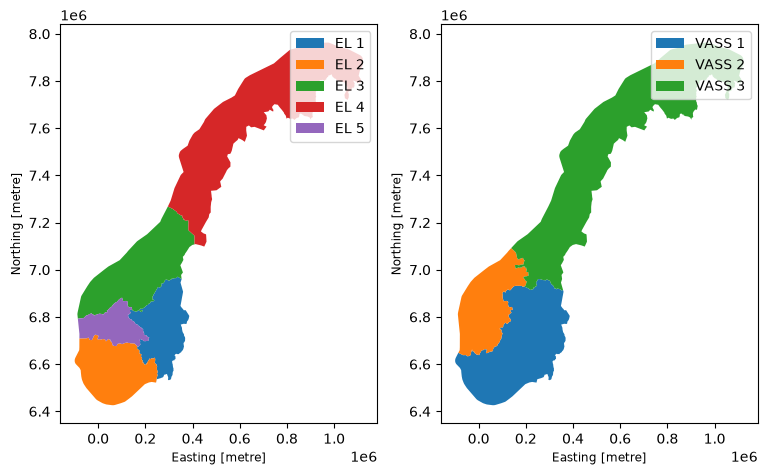

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 6))
areas[:5].reset_index().plot("area", legend=True, ax=axes[0])
areas[5:].reset_index().plot("area", legend=True, ax=axes[1]);

In [8]:
# fetch reservoir stats (NO 0, EL 1-5, VASS 1-3)
BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
raw = pd.DataFrame(requests.get(f"{BASE}/HentOffentligData", timeout=60).json())
raw["dato_Id"] = pd.to_datetime(raw["dato_Id"])

print(raw.groupby("omrType")["omrnr"].unique())

omrType
EL      [1, 4, 3, 5, 2]
NO                  [0]
VASS          [2, 3, 1]
Name: omrnr, dtype: object


In [9]:
# grab 1000 random points per area
sample = areas.geometry.sample_points(1000, rng=0).to_crs(4326)
# extract coords and save to json
points = {area: [[round(p.x, 4), round(p.y, 4)] for p in mp.geoms] for area, mp in sample.items()}
json.dump(points, open("data/sample_points.json", "w"))
print({area: len(p) for area, p in points.items()})

{'EL 1': 1000, 'EL 2': 1000, 'EL 3': 1000, 'EL 4': 1000, 'EL 5': 1000, 'VASS 1': 1000, 'VASS 2': 1000, 'VASS 3': 1000}


* Use the open-meteo API to retrieve hourly historical reanalysis data using the ERA5 model for a single location as follows:
   * Create a function for the API download task that takes a region identifier plus a time interval as input, looks up the corresponding list of pairs of longitude and latitude values and downloads at least precipitation and temperature, but include any relevant property you find.
   * Apply the function to download data for NO3 for 2024.

In [10]:
def download_weather(region, start, end, n_points=20,
                     variables=("temperature_2m", "precipitation", "rain", "snowfall", "wind_speed_10m", "wind_gusts_10m")):
    points = random.Random(0).sample(json.load(open("data/sample_points.json"))[region], n_points)
    frames = []
    # batch in chunks of 10
    for i in range(0, n_points, 10):                                 
        batch = points[i:i + 10]
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=120, params={
            "latitude": ",".join(str(lat) for lon, lat in batch), "longitude": ",".join(str(lon) for lon, lat in batch),
            "start_date": start, "end_date": end, "hourly": ",".join(variables), "models": "era5"})
        if r.status_code != 200:
            raise RuntimeError(r.json()["reason"])
        data = r.json()
        # handle single vs multi response format
        for loc in data if isinstance(data, list) else [data]:   
            frames.append(pd.DataFrame(loc["hourly"]).set_index("time").rename(columns=lambda c: c.removesuffix("_era5")))
    # mean across all sampled points
    weather = pd.concat(frames).groupby(level=0).mean() 
    weather.index = pd.to_datetime(weather.index)
    return weather

In [11]:
weather = download_weather("EL 3", "2024-01-01", "2024-12-31") 
print(weather.shape)
weather.head()

(8784, 6)


,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,wind_gusts_10m
time,,,,,,
2024-01-01 00:00:00,-4.240,0.01,0.0,0.007,21.660,50.620
2024-01-01 01:00:00,-4.375,0.01,0.0,0.007,22.130,51.055
2024-01-01 02:00:00,-4.370,0.01,0.0,0.007,22.565,51.205
2024-01-01 03:00:00,-4.440,0.01,0.0,0.007,22.545,51.055
2024-01-01 04:00:00,-4.390,0.01,0.0,0.007,22.750,50.905


### Outliers and anomalies:
* Plot the average precipitation as a function of time.

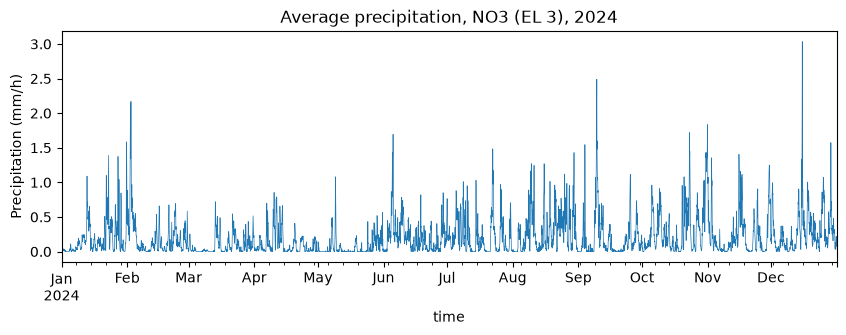

In [12]:
# plot hourly precip
weather["precipitation"].plot(figsize=(10, 3), lw=0.5, ylabel="Precipitation (mm/h)", title="Average precipitation, NO3 (EL 3), 2024");

   * Perform a high-pass filtering of the precipitation using the Discrete Cosine Transform to create seasonally adjusted temperature variations (SATV).
   * Add curves to the plot indicating Statistical Process Control boundaries between inliers and outliers based on the SATV according to robust statistics estimated from the whole year. Colour outliers with a contrasting colour. Do not plot SATV values; only use them to find boundaries and outliers.
   * Let the frequency cut-off for the DCT and the number of standard deviations be parameters with sensible defaults.
   * Wrap this in a function that returns the plot and relevant summaries of the outliers, and test the function.

In [13]:
def spc_outliers(series, cutoff=0.03, n_std=3.0, label="value"):
  x = series.interpolate()
  coef = dct(x.values, norm="ortho")
  # zero out low frequencies for high-pass filter
  coef[: int(cutoff * 2 * len(x) / 24)] = 0
  satv = idct(coef, norm="ortho")
  centre = np.median(satv)
  # robust std via mad
  sigma = 1.4826 * np.median(np.abs(satv - centre))
  # find points outside bounds
  out = np.abs(satv - centre) > n_std * sigma
  # dynamic baseline for limits
  mid = x.values - satv + centre

  fig = Figure(figsize=(10, 4))
  ax = fig.subplots()
  ax.plot(x.index, x, lw=0.6, label=label)
  ax.plot(
      x.index,
      mid + n_std * sigma,
      "k--",
      lw=1,
      label=f"Limits ({n_std:g} robust std)",)
  ax.plot(x.index, mid - n_std * sigma, "k--", lw=1)
  ax.scatter(
      x.index[out], x[out], s=8, color="red", zorder=3, label="Outliers")
  ax.set_ylabel(label)
  ax.legend(loc="upper right")

  return fig, {
      "n": len(x),
      "outliers": out.sum(),
      "share": out.mean(),
      "robust_std": sigma,
      "table": x[out].to_frame(label),}

In [14]:
# test spc with default params
fig, summary = spc_outliers(weather["precipitation"], label="Precipitation (mm/h)")
print(f"{summary['outliers']} of {summary['n']} hours are outliers ({summary['share']:.1%}), robust std {summary['robust_std']:.3f}")
display(summary["table"].head())

608 of 8784 hours are outliers (6.9%), robust std 0.160


,Precipitation (mm/h)
time,
2024-01-12 21:00:00,0.595
2024-01-12 22:00:00,0.875
2024-01-12 23:00:00,0.990
2024-01-13 00:00:00,1.090
2024-01-13 01:00:00,0.930


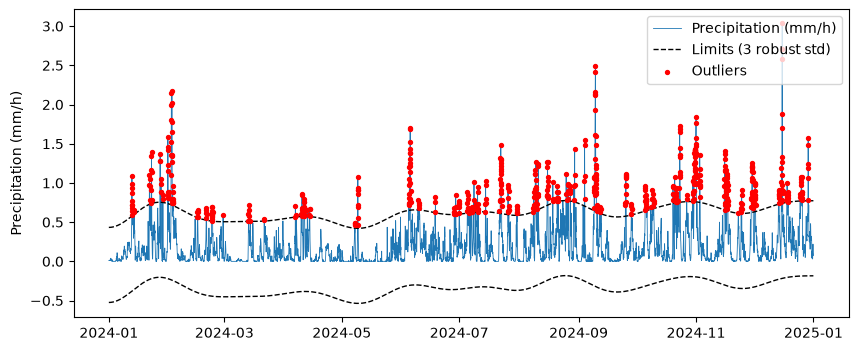

In [15]:
fig

In [16]:
# test with higher cutoff and wider limits
fig, summary = spc_outliers(weather["precipitation"], cutoff=0.1, n_std=4, label="Precipitation (mm/h)")
print(f"{summary['outliers']} of {summary['n']} hours are outliers ({summary['share']:.1%}), robust std {summary['robust_std']:.3f}")

258 of 8784 hours are outliers (2.9%), robust std 0.146


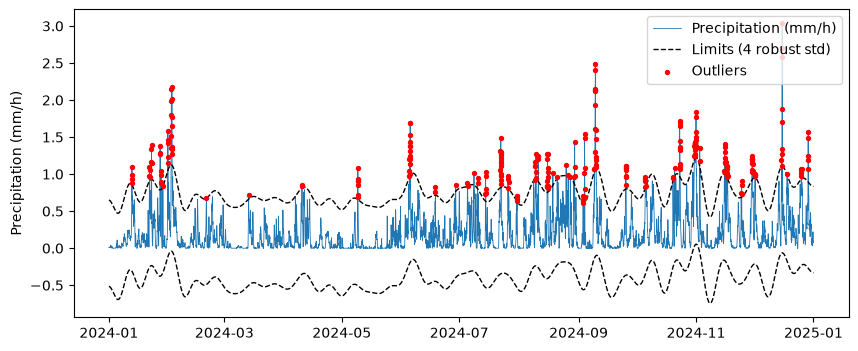

In [17]:
fig

In [18]:
# test on temperature
fig, summary = spc_outliers(weather["temperature_2m"], label="Temperature (°C)")
print(f"{summary['outliers']} of {summary['n']} hours are outliers ({summary['share']:.1%}), robust std {summary['robust_std']:.3f}")

8 of 8784 hours are outliers (0.1%), robust std 3.270


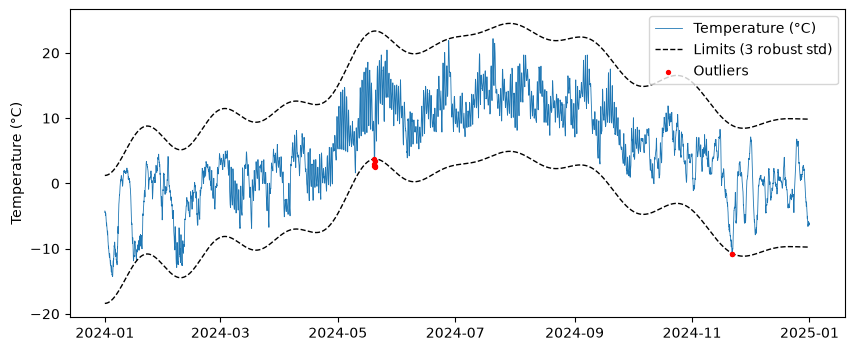

In [19]:
fig

* Plot the average temperature as a function of time.

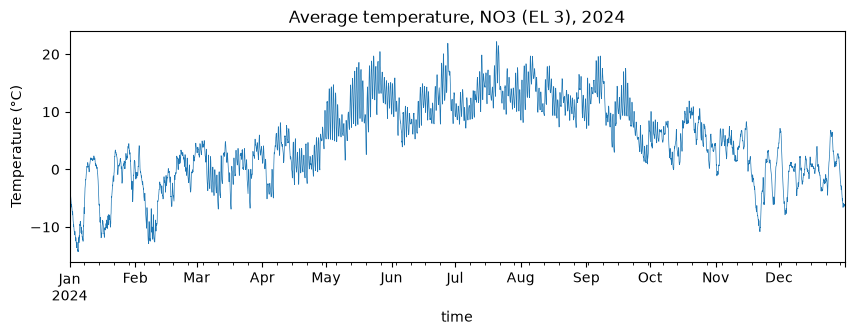

In [20]:
weather["temperature_2m"].plot(figsize=(10, 3), lw=0.5, ylabel="Temperature (°C)", title="Average temperature, NO3 (EL 3), 2024");

   * Indicate anomalies according to the Local Outlier Factor method.
   * Let the proportion of outliers be a parameter defaulting to 1%.
   * Wrap this in a function that returns the plot and relevant summaries of the outliers, and test the function.

In [21]:
def lof_anomalies(series, contamination=0.01, n_neighbors=20, label="value"):
  x = series.interpolate()

  # value in std units, time scaled to 20 units
  points = np.c_[(x.values - x.mean()) / x.std(), np.linspace(0, 20, len(x))]

  lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
  flag = lof.fit_predict(points) == -1  # -1 = anomaly

  fig = Figure(figsize=(10, 4))
  ax = fig.subplots()
  ax.plot(x.index, x, lw=0.6, label=label)
  ax.scatter(x.index[flag], x[flag], s=10, color="red", zorder=3, label="Anomalies")
  ax.set_ylabel(label)
  ax.legend(loc="upper right")

  table = pd.DataFrame({
      label: x[flag],
      "LOF score": -lof.negative_outlier_factor_[flag],
  }).sort_values("LOF score", ascending=False)

  return fig, {
      "n": len(x),
      "anomalies": flag.sum(),
      "share": flag.mean(),
      "table": table,}

In [22]:
# test lof anomalies with default 1% contamination
fig, summary = lof_anomalies(weather["temperature_2m"], label="Temperature (°C)")
print(f"{summary['anomalies']} of {summary['n']} hours are anomalies ({summary['share']:.1%})")
display(summary["table"].head())


88 of 8784 hours are anomalies (1.0%)


,Temperature (°C),LOF score
time,,
2024-01-20 15:00:00,-6.885,2.285607
2024-12-23 22:00:00,-4.485,2.248408
2024-05-10 03:00:00,1.595,2.057784
2024-05-10 02:00:00,1.775,1.991910
2024-07-13 13:00:00,19.345,1.990886


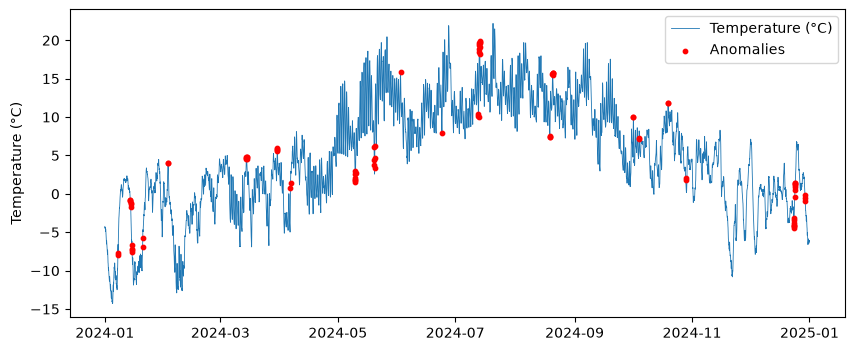

In [23]:
fig

In [24]:
# test lof anomalies with 5% contamination and 50 neighbors
fig, summary = lof_anomalies(weather["temperature_2m"], contamination=0.05, n_neighbors=50, label="Temperature (°C)")
print(f"{summary['anomalies']} of {summary['n']} hours are anomalies ({summary['share']:.1%})")

440 of 8784 hours are anomalies (5.0%)


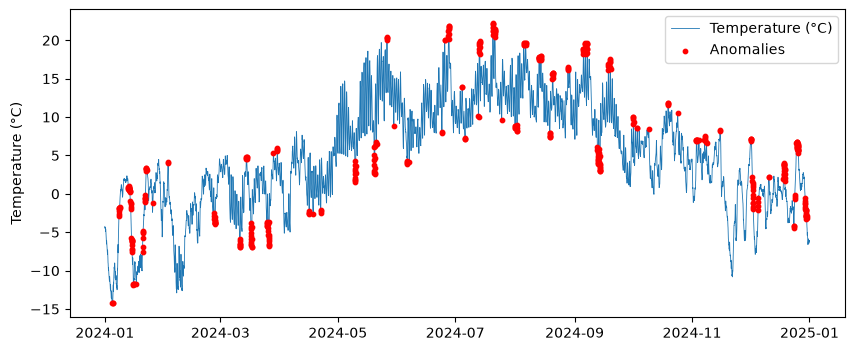

In [25]:
fig

### Seasonal-Trend decomposition using LOESS (STL)
* Perform STL on the degree of filling from the magasinstatistikk data and plot its decomposition.
* Let the seasonal smoother, trend smoother and robust (true/false) be parameters, and give each of them sensible defaults.
* Wrap this in a function that returns the plot, and test the function.

In [26]:
# get weekly filling degree for all of norway
fill = raw[raw["omrType"] == "NO"].set_index("dato_Id").sort_index()["fyllingsgrad"]
print(fill.shape, fill.index.min().date(), "to", fill.index.max().date())

(1661,) 1995-01-08 to 2026-11-01


In [27]:
def stl_plot(series, seasonal=13, trend=105, robust=True):
  # stl decomposition on a regular weekly grid with gap interpolation
  res = STL(
      series.asfreq("7D").interpolate(),
      period=52,
      seasonal=seasonal,
      trend=trend,
      robust=robust,
  ).fit()
  fig = Figure(figsize=(10, 7), layout="constrained")
  parts = {
      "Observed": res.observed,
      "Trend": res.trend,
      "Seasonal": res.seasonal,
      "Residual": res.resid,}
  # one subplot per component
  for ax, (name, part) in zip(fig.subplots(4, 1, sharex=True), parts.items()):
    ax.plot(part, lw=0.8)
    ax.set_ylabel(name)
    fig.suptitle(f"STL: seasonal={seasonal}, trend={trend}, robust={robust}")
  return fig

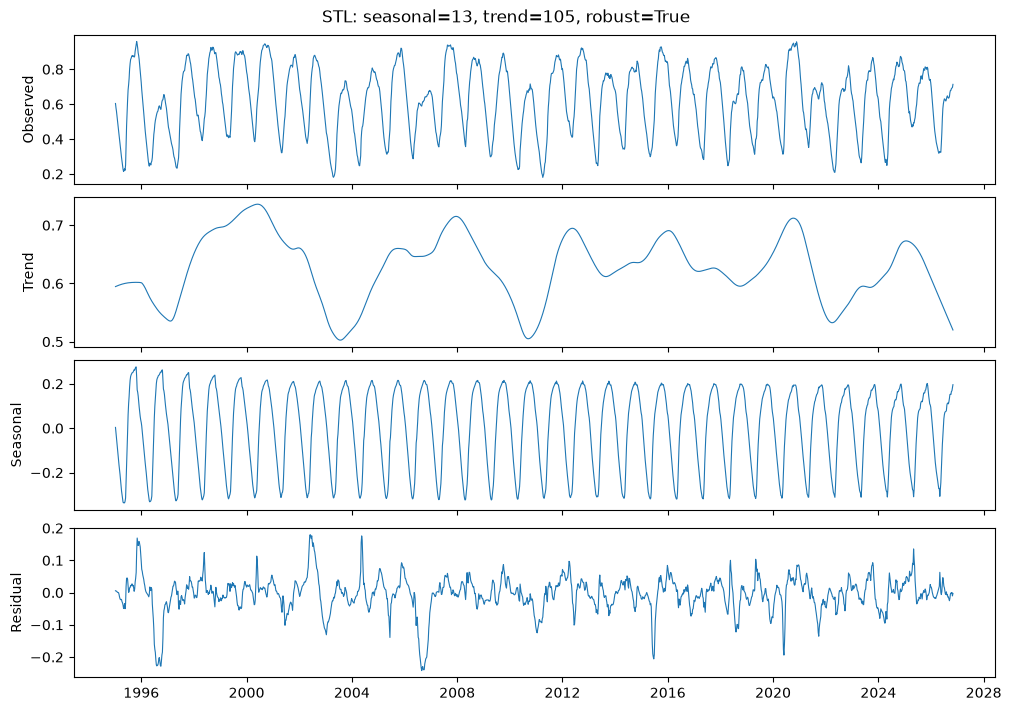

In [28]:
#test with default parameters
stl_plot(fill)

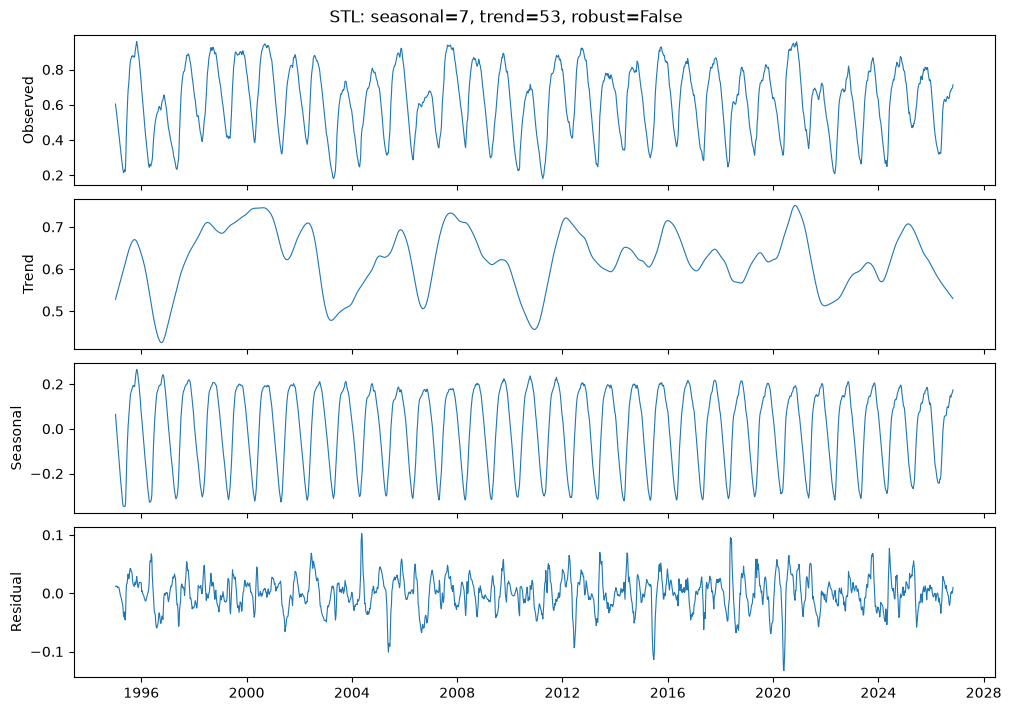

In [29]:
#test with smaller smoothers, not robust
stl_plot(fill, seasonal=7, trend=53, robust=False)

### Spectrogram
* Create a spectrogram based on the same data.
* Let the window length and window overlap be parameters, and give each of them sensible defaults.
* Wrap this in a function that returns the plot, and test the function.

In [30]:
def spectrogram_plot(series, window=156, overlap=78):
    f, t, power = spectrogram(series.interpolate().values, fs=52, nperseg=window, noverlap=overlap)    # fs = 52 weeks per year
    fig = Figure(figsize=(10, 4), layout="constrained")
    ax = fig.subplots()
    # convert time array to years and plot pcolormesh
    mesh = ax.pcolormesh(series.index[0].year + t, f, 10 * np.log10(power), shading="gouraud")         # t in years
    ax.set_ylim(0, 6)
    ax.set(xlabel="Year", ylabel="Frequency (cycles per year)", title=f"Window {window} weeks, overlap {overlap} weeks")
    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    return fig

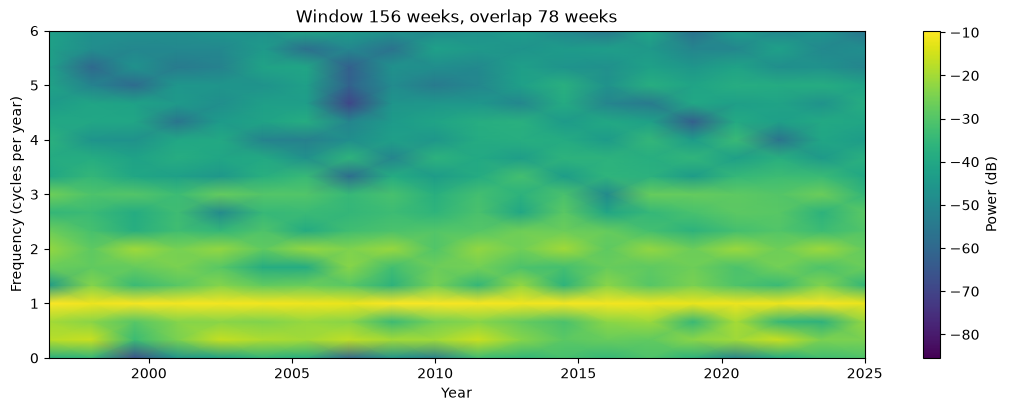

In [31]:
# test with default parameters
spectrogram_plot(fill)

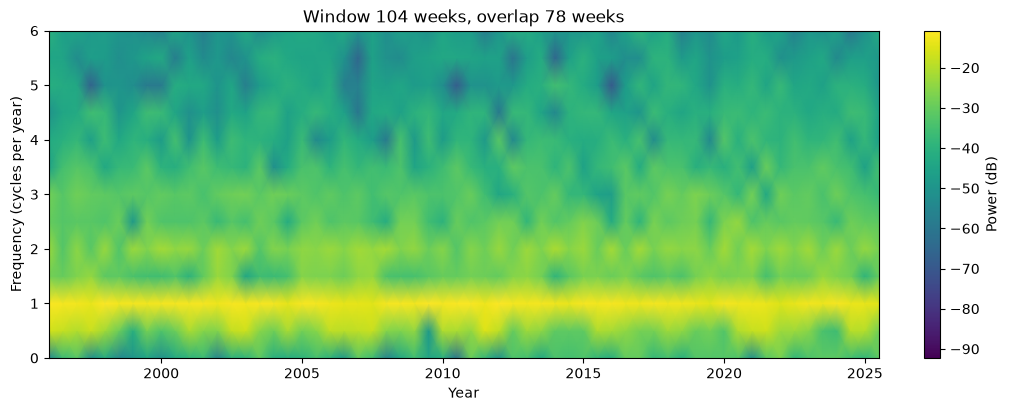

In [32]:
#tst with 2years window, 75% overlap
spectrogram_plot(fill, window=104, overlap=78)

## Streamlit app
- Update your Streamlit app from part 2 of the project according to the following points.
    - Note! For each of the new pages below, consider whether you can depend on an existing area selector or need a local one. Also, consider if this should be a global or local setting.
    - Meteorological data:
        - Let the choice of downloaded data depend on the selector that is used for the magasinstatistikk.
        - Consider if you need a separate page for download control and confirmation, or if this can be an integrated, hidden part of the web app.
    - On one new page, use st.tabs() and fill the first tab with the STL analysis and the second tab with the Spectrogram. Add necessary UI elements and plots to both.
    - On a second new page, use st.tabs() and fill the first tab with the Outlier/SPC analysis and the second tab with the Anomaly/LOF analysis. Add necessary UI elements, plots and statistics to both.
    - Reorder any pages according to good logic and natural grouping.

### <font color="green">Answer to the task:</font>
- page 2 (reservoir table) and page 3 (reservoir plot) are unchanged. Page 4 is the new stl and spectrogram page and page 5 is the new outliers (spc) and anomalies (lof) page, both with st.tabs(). The cross border flows page is now page 6, so the reservoir pages, the weather page and the flow page are grouped.
- the selector on page 2 only exists on that page, so pages 4 and 5 have a local selector with the same options and data. A global setting is not needed because each page shows one area at a time.
- the weather download is an integrated, hidden part of page 5. it starts when an area and a year are chosen, shows a spinner and is cached for 24 hours, so there is no separate download page. Whole Norway has no weather region, so page 5 asks for el or vass.

In [33]:
note = "# Generated from notebooks/project_work_part3.ipynb: change the notebook, not this file\n"
weather_imports = "import json\nimport random\n\nimport pandas as pd\nimport requests\n\n\n"
analysis_imports = ("import numpy as np\nimport pandas as pd\nfrom matplotlib.figure import Figure\nfrom scipy.fft import dct, idct\n"
                    "from scipy.signal import spectrogram\nfrom sklearn.neighbors import LocalOutlierFactor\n"
                    "from statsmodels.tsa.seasonal import STL\n\n\n")
# write weather module
Path("modules/weather.py").write_text(note + weather_imports + inspect.getsource(download_weather))
# write analysis module
Path("modules/analysis.py").write_text(note + analysis_imports + "\n\n".join(
    inspect.getsource(f) for f in (spc_outliers, lof_anomalies, stl_plot, spectrogram_plot)));

## Screencast
- 5-minute screencast where you briefly showcase your running app and explain what your code does.
    - Canvas does not permit upload of more than one file in the assignment.
    - If you make a screencast in Panopto, you can share a link to your video and add the link to the Jupyter Notebook or as a submission comment (make sure the file permissions are open for anyone, as the default is locked and private).
    - If you use a different tool for making the screencast, you can upload your video to the GitHub repo.

### <font color="green">Answer to the task:</font>

In [37]:
from IPython.display import Video
Video("../video/video.ind320-kompresed- part 3.mp4", width=600)


ValueError: To embed videos, you must pass embed=True (this may make your notebook files huge)
Consider passing Video(url='...')

## AI usage

during part 3 of the project, i used gemini primarily as a technical co pilot and debugging assistant. specifically, i consulted ai to help structure the api requests for the open meteo era5 historical archive and batching 1,000 sampled coordinates. i also used ai guidance to implement the discrete cosine transform (dct) for high pass filtering in precipitation spc, configure the local outlier factor (lof) method for temperature anomalies, and set up stl decomposition and spectrograms. all code was tested, modified, and integrated locally into my jupyter notebook and streamlit application.

## Developers log

the first surprise was the shapefile nve_region printed out rã instead of rø because it didn't have a code page attached. reading it in as utf-8 fixed that right up. magasinstatistikk only covers three vass areas, so i had to merge the five precipitation regions first before doing any sampling. sample_points(..., random_state=42) kept spitting out different points every time because that argument gets completely ignored, turns out setting rng=0 is what actually gives you reproducible results. the 1000 points per region are saved in data/sample_points.json, so both the notebook and the app use the exact same locations.

the other thig is checking the docs, i realized a request counts as locations x days/14 x variables/10 calls. getting all 1000 locations for a full year would take around 15700 calls, which easily blows past the daily limit of 10000. so download_weather averages out n_points random locations (20 in the notebook, 10 in the app), pulling 10 per request. i basically interpreted "a single location" in the task as one region represented by its average.

for the spc and lof part i just stuck to the textbook here. for spc, the precipitation data gets high pass filtered using dct coefficients below the cut off frequency are zeroed out, and taking the inverse transform gives you the satv (which i only use for calculations and never plot). since coefficient k corresponds to the frequency k/(2n dt), i had to convert the cut off from cycles per day over to an index. the center is set to the median, and the standard deviation is 1.4826 x mad of the satv across the whole year. the bounds are calculated as the slow moving part of the series plus or minus n standard deviations, so they naturally track seasonal changes. since it mostly doesn't rain, the rainy hours pop out as obvious outliers. for lof, each hour is treated as a point with two features, the value in standard deviations and time scaled to 20 units. looking at the value alone meant lof only picked up the most extreme temperature spikes, but factoring in time lets it spot local anomalies too.

the stl needs a regular time series with a set period, so i went with the weekly data using a period of 52. both smoothers have to be odd numbers and the trend smoother has to be larger than the period, which pretty much set the ranges for the sliders. the spectrogram is plotted in cycles per year, so the annual cycle shows up right at 1.

for the streamlit part i moved the flow page over to page_6.py. the selector on page 2 doesn't carry over between pages, meaning every new page gets its own local selector. the download function is tucked away inside page 5 and cached for 24 hours so open meteo doesn't block requests from shared servers; if something goes wrong, the page just shows a clean error message instead of crashing. i used matplotlib figure objects with st.pyplot, and whenever i had two selectboxes sharing the same label, i made sure to give them unique key parameters.

## Evaluation
- The uploaded PDF, GitHub repository, Streamlit app, and screencast will be assessed according to the recipe above.
    - By one fellow student in peer review.
    - By Liland or Osman.
- TA/Teacher's feedback will be short and instructive regarding points of improvement and fulfilment of requirements.
- Final fulfilment of the course will be based on the four rounds of hand-ins seen as a whole.